## Rossmann Store Sales – Kaggle Competition
### Problem: Rossmann operates thousands of drugstores across Europe. Daily sales vary depending on factors such as promotions, holidays, seasonality, competition, and store characteristics. The challenge is to accurately predict daily sales for individual stores based on historical sales data and relevant business factors.
### Goal: Develop a Machine Learning model to forecast daily sales for each Rossmann store up to six weeks in advance, minimizing prediction errors and supporting better business planning, inventory management, and resource allocation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

In [31]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ----- ---------------------------------- 6.8/48.9 MB 34.0 MB/s eta 0:00:02
   ---------------- ----------------------- 20.4/48.9 MB 51.1 MB/s eta 0:00:01
   ----------------------------- ---------- 36.4/48.9 MB 60.5 MB/s eta 0:00:01
   ---------------------------------------  48.2/48.9 MB 60.0 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 56.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


### Data Loading

In [2]:
#1-2
base_path = Path(r'C:\Projects\AI Projects\2. Prediccion de ventas por tienda\data')
train = pd.read_csv(base_path / 'train_salespredictions.csv',
                 dtype={'StateHoliday': str},
                 parse_dates=['Date'])

test = pd.read_csv(base_path / 'test_salespredictions.csv',
                 dtype={'StateHoliday': str},
                 parse_dates=['Date'])

store = pd.read_csv(base_path / "store_salespredictions.csv")

display(train.head(5).style.hide(axis='index'))


Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1,5,2015-07-31 00:00:00,5263,555,1,1,0,1
2,5,2015-07-31 00:00:00,6064,625,1,1,0,1
3,5,2015-07-31 00:00:00,8314,821,1,1,0,1
4,5,2015-07-31 00:00:00,13995,1498,1,1,0,1
5,5,2015-07-31 00:00:00,4822,559,1,1,0,1


In [6]:
for col in ['Open', 'Promo', 'StateHoliday', 'SchoolHoliday']:
    print(col, train[col].value_counts().to_dict())

Open {1: 844392, 0: 172817}
Promo {0: 629129, 1: 388080}
StateHoliday {'0': 986159, 'a': 20260, 'b': 6690, 'c': 4100}
SchoolHoliday {0: 835488, 1: 181721}


In [5]:
print(train.shape, test.shape, store.shape)

(1017209, 9) (41088, 8) (1115, 10)


### Data Cleaning
- 1–2	Loaded the data; converted Date to datetime and StateHoliday to a category
- 3	Filled the missing Open values for store 622 in test with 1
- 4	Created 4 closure features (ClosedYesterday, ClosedTomorrow, DaysSinceClosed, DaysToClosed) on train + test combined, before filtering
- 5	Merged store into the combined data
- 6	Handled missing competition and Promo2 values, and added competitor age in months (CompetitionOpenMonths, CompetitionActive)
- 7	Added Promo2 features: active on date, relaunch month, weeks since joining (Promo2Active, Promo2Month, Promo2Weeks)
- 8	Split train/test again; filtered train to open days with sales > 0, kept test complete
- 9	Saved train_clean and test_clean as parquet

In [7]:
empty = test["Open"].isna()
print(empty.sum())
print(test.loc[empty, ["Store", "Open", "Date", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday"]])

11
       Store  Open       Date  DayOfWeek  Promo StateHoliday  SchoolHoliday
479      622   NaN 2015-09-17          4      1            0              0
1335     622   NaN 2015-09-16          3      1            0              0
2191     622   NaN 2015-09-15          2      1            0              0
3047     622   NaN 2015-09-14          1      1            0              0
4759     622   NaN 2015-09-12          6      0            0              0
5615     622   NaN 2015-09-11          5      0            0              0
6471     622   NaN 2015-09-10          4      0            0              0
7327     622   NaN 2015-09-09          3      0            0              0
8183     622   NaN 2015-09-08          2      0            0              0
9039     622   NaN 2015-09-07          1      0            0              0
10751    622   NaN 2015-09-05          6      0            0              0


In [35]:
# 3 replace Open w/ 1
cond = (test["Store"] == 622) & (test["Open"].isna())
test.loc[cond, "Open"] = 1
test["Open"] = test["Open"].astype(int)

In [8]:
### Concatenate train/test

full = pd.concat([train.assign(set="train"), test.assign(set="test")],
                 ignore_index=True)
full = full.sort_values(["Store", "Date"]).reset_index(drop=True)

print(full.shape)                     
print(full["set"].value_counts())     

(1058297, 11)
set
train    1017209
test       41088
Name: count, dtype: int64


In [9]:
### 4 Creating new columns - ClosedYesterday / ClosedTomorrow / DaysSinceClosed / DaysToClosed
### Bussines rules: when a store closes, the day before or after sales increase significantly.
### Result: almost 17% of the stores has a yesterday and tomorrow closed days.

In [10]:
closed = full["Open"] == 0
closed_days = set(zip(full.loc[closed, "Store"], full.loc[closed, "Date"]))

one_day = pd.Timedelta(days=1)
full["ClosedYesterday"] = [int((s, d - one_day) in closed_days) for s, d in zip(full["Store"], full["Date"])]
full["ClosedTomorrow"]  = [int((s, d + one_day) in closed_days) for s, d in zip(full["Store"], full["Date"])]

print(full[["ClosedYesterday", "ClosedTomorrow"]].mean())

ClosedYesterday    0.168947
ClosedTomorrow     0.167746
dtype: float64


In [11]:
### Creating new columns - DaysSinceClosed / DaysToClosed
### Result: almost 17% of the stores has a yesterday and tomorrow closed days.

In [12]:
CAP = 60
closed_date = full["Date"].where(closed)   # la fecha si cerró, NaT si estuvo abierta

last_closed = closed_date.groupby(full["Store"]).ffill()   # último cierre (hacia atrás)
next_closed = closed_date.groupby(full["Store"]).bfill()   # próximo cierre (hacia adelante)

full["DaysSinceClosed"] = (full["Date"] - last_closed).dt.days.fillna(CAP).clip(upper=CAP).astype(int)
full["DaysToClosed"]    = (next_closed - full["Date"]).dt.days.fillna(CAP).clip(upper=CAP).astype(int)

In [13]:
### Almost stores are closed once a week (Sundays) and the other values represents the holidays days
print((full["DaysSinceClosed"] >= 60).mean())   # % de filas que tocan el tope
print(full["DaysSinceClosed"].value_counts().sort_index().head(15))

0.01958240456129045
DaysSinceClosed
0     178801
1     167434
2     160038
3     146614
4     134668
5     126451
6     118727
7        203
8        201
9        200
10       183
11       167
12       160
13       145
14       121
Name: count, dtype: int64


In [14]:
### 5 Merge w/store file

n_before = len(full)
full = full.merge(store, on="Store", how="left", validate="many_to_one")

print(n_before, len(full))
print(full.shape)         


1058297 1058297
(1058297, 24)


In [15]:
display(full.head(5).style.hide(axis='index'))

Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,set,Id,ClosedYesterday,ClosedTomorrow,DaysSinceClosed,DaysToClosed,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1,2,2013-01-01 00:00:00,0.000000,0.000000,0.000000,0,a,1,train,nan,0,0,0,0,c,a,1270.000000,9.000000,2008.000000,0,nan,nan,nan
1,3,2013-01-02 00:00:00,5530.000000,668.000000,1.000000,0,0,1,train,nan,1,0,1,4,c,a,1270.000000,9.000000,2008.000000,0,nan,nan,nan
1,4,2013-01-03 00:00:00,4327.000000,578.000000,1.000000,0,0,1,train,nan,0,0,2,3,c,a,1270.000000,9.000000,2008.000000,0,nan,nan,nan
1,5,2013-01-04 00:00:00,4486.000000,619.000000,1.000000,0,0,1,train,nan,0,0,3,2,c,a,1270.000000,9.000000,2008.000000,0,nan,nan,nan
1,6,2013-01-05 00:00:00,4997.000000,635.000000,1.000000,0,0,1,train,nan,0,1,4,1,c,a,1270.000000,9.000000,2008.000000,0,nan,nan,nan


In [16]:
# 6 Handled missing competition and Promo2 values

cols_na = ["CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
           "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
for c in cols_na:
    print(c, full.loc[full[c].isna(), "Store"].nunique(), "tiendas")

CompetitionDistance 3 tiendas
CompetitionOpenSinceMonth 354 tiendas
CompetitionOpenSinceYear 354 tiendas
Promo2SinceWeek 544 tiendas
Promo2SinceYear 544 tiendas
PromoInterval 544 tiendas


In [17]:
### Competition distance - replace w/100000 too far away
full["CompDistMissing"] = full["CompetitionDistance"].isna().astype(int)
full["CompetitionDistance"] = full["CompetitionDistance"].fillna(100_000)

In [18]:
### Competitor store but didn't know from when
full["CompOpenMissing"] = full["CompetitionOpenSinceYear"].isna().astype(int)

full["CompetitionOpenMonths"] = (
    (full["Date"].dt.year  - full["CompetitionOpenSinceYear"]) * 12
  + (full["Date"].dt.month - full["CompetitionOpenSinceMonth"])
)

# The competitor was opened?
full["CompetitionActive"] = np.where(
    full["CompOpenMissing"] == 1, 1,                    
    (full["CompetitionOpenMonths"] >= 0).astype(int)    
)

In [19]:
###  7 Store no participan in Promo2
print(store.loc[store["Promo2"] == 0, ["Promo2SinceWeek", "PromoInterval"]].isna().all())  # True, True
print(store.loc[store["Promo2"] == 1, ["Promo2SinceWeek", "PromoInterval"]].isna().sum())  # 0, 0

Promo2SinceWeek    True
PromoInterval      True
dtype: bool
Promo2SinceWeek    0
PromoInterval      0
dtype: int64


In [20]:
full[["Promo2SinceWeek", "Promo2SinceYear"]] = full[["Promo2SinceWeek", "Promo2SinceYear"]].fillna(0)
full["PromoInterval"] = full["PromoInterval"].fillna("None")

In [21]:
print(full.isna().sum()[full.isna().sum() > 0])

Sales                          41088
Customers                      41088
Open                              11
Id                           1017209
CompetitionOpenSinceMonth     338564
CompetitionOpenSinceYear      338564
CompetitionOpenMonths         338564
dtype: int64


In [22]:
### Promo2 Active - from date / Promo2Start
st = store[["Store", "Promo2SinceYear", "Promo2SinceWeek"]].dropna()   # only the participant stores

st["Promo2Start"] = pd.to_datetime(
    st["Promo2SinceYear"].astype(int).astype(str) + "-"
    + st["Promo2SinceWeek"].astype(int).astype(str) + "-1",
    format="%G-%V-%u"
)
print(st.head())

full = full.merge(st[["Store", "Promo2Start"]], on="Store", how="left")

    Store  Promo2SinceYear  Promo2SinceWeek Promo2Start
1       2           2010.0             13.0  2010-03-29
2       3           2011.0             14.0  2011-04-04
10     11           2012.0              1.0  2012-01-02
11     12           2010.0             13.0  2010-03-29
12     13           2009.0             45.0  2009-11-02


In [23]:
month_map = {1:"Jan", 2:"Feb", 3:"Mar", 4:"Apr", 5:"May", 6:"Jun",
             7:"Jul", 8:"Aug", 9:"Sept", 10:"Oct", 11:"Nov", 12:"Dec"}
month_txt = full["Date"].dt.month.map(month_map)

full["Promo2Active"] = (full["Date"] >= full["Promo2Start"]).astype(int)

in_interval = [m in iv.split(",") for m, iv in zip(month_txt, full["PromoInterval"])]
full["Promo2Month"] = (full["Promo2Active"].astype(bool) & np.array(in_interval)).astype(int)

full["Promo2Weeks"] = np.where(
    full["Promo2Active"] == 1,
    (full["Date"] - full["Promo2Start"]).dt.days // 7,
    0
)

full["Promo2Weeks"] = full["Promo2Weeks"].astype(int)

In [24]:
print(full.groupby("set")[["Promo2Active", "Promo2Month"]].mean().round(3))

print(full[full["set"] == "test"].groupby("PromoInterval")["Promo2Month"].mean().round(2))

print(full.loc[full["Store"] == 2, ["Date", "Promo2Start", "Promo2Active",
                                    "Promo2Month", "Promo2Weeks"]].iloc[[0, 30, 200]])

       Promo2Active  Promo2Month
set                             
test          0.581        0.127
train         0.432        0.149
PromoInterval
Feb,May,Aug,Nov     0.65
Jan,Apr,Jul,Oct     0.00
Mar,Jun,Sept,Dec    0.35
None                0.00
Name: Promo2Month, dtype: float64
           Date Promo2Start  Promo2Active  Promo2Month  Promo2Weeks
990  2013-01-01  2010-03-29             1            1          144
1020 2013-01-31  2010-03-29             1            1          148
1190 2013-07-20  2010-03-29             1            1          172


In [25]:
### 8 Split train / test
train_clean = full[full["set"] == "train"].copy()
test_clean  = full[full["set"] == "test"].copy()
print(train_clean.shape, test_clean.shape)   

(1017209, 32) (41088, 32)


In [26]:
### Filter train: 0 means closed or sales = 0 errors
n_closed = (train_clean["Open"] == 0).sum()
n_zero   = ((train_clean["Open"] == 1) & (train_clean["Sales"] == 0)).sum()
print("Closed:", n_closed, "| Opened w/sales in 0:", n_zero)   

train_clean = train_clean[(train_clean["Open"] == 1) & (train_clean["Sales"] > 0)]
print(train_clean.shape)   

Closed: 172817 | Opened w/sales in 0: 54
(844338, 32)


In [27]:
### Ordering columns

# Train: Id no apply; Promo2Start is not neccesary
train_clean = train_clean.drop(columns=["set", "Id", "Promo2Start"])
train_clean[["Sales", "Customers"]] = train_clean[["Sales", "Customers"]].astype(int)

# Test: Sales/Customers are not in test; Id is neccesary
test_clean = test_clean.drop(columns=["set", "Sales", "Customers", "Promo2Start"])
test_clean["Id"] = test_clean["Id"].astype(int)
test_clean = test_clean.sort_values("Id").reset_index(drop=True)
train_clean = train_clean.reset_index(drop=True)

In [28]:
print(train_clean.shape, test_clean.shape)
print(train_clean.isna().sum()[train_clean.isna().sum() > 0])
print(test_clean.isna().sum()[test_clean.isna().sum() > 0])
print(test_clean["Open"].value_counts())
print(set(train_clean.columns) - set(test_clean.columns))
print(set(test_clean.columns) - set(train_clean.columns))

(844338, 29) (41088, 28)
CompetitionOpenSinceMonth    268600
CompetitionOpenSinceYear     268600
CompetitionOpenMonths        268600
dtype: int64
Open                            11
CompetitionOpenSinceMonth    15216
CompetitionOpenSinceYear     15216
CompetitionOpenMonths        15216
dtype: int64
Open
1.0    35093
0.0     5984
Name: count, dtype: int64
{'Customers', 'Sales'}
{'Id'}


In [29]:
# 9 Save the files parquet type
out = base_path / "clean"
out.mkdir(exist_ok=True)

train_clean.to_parquet(out / "train_clean.parquet", index=False)
test_clean.to_parquet(out / "test_clean.parquet", index=False)

### EDA PLAN
1. Sales over time - How are sales distributed? Is there a trend or seasonality?
2. Day of week - Which days sell the most? How does that interact with promos?
3. Promos - How much does a promo lift sales? 
4. Competition	Effect of competitor distance, and what happens when a competitor opens
5. Promo2 - Does the relaunch month sell more?
6. August/September - How did the test period behave in 2013 and 2014?

In [30]:
# Set up
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

tr = pd.read_parquet(base_path / "clean" / "train_clean.parquet")

COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=COL),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.figsize": (11, 4.5), "lines.linewidth": 2,
})
miles = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # 7.000 en vez de 7000

tr["Year"]  = tr["Date"].dt.year
tr["Month"] = tr["Date"].dt.month
tr["Week"]  = tr["Date"].dt.isocalendar().week.astype(int)

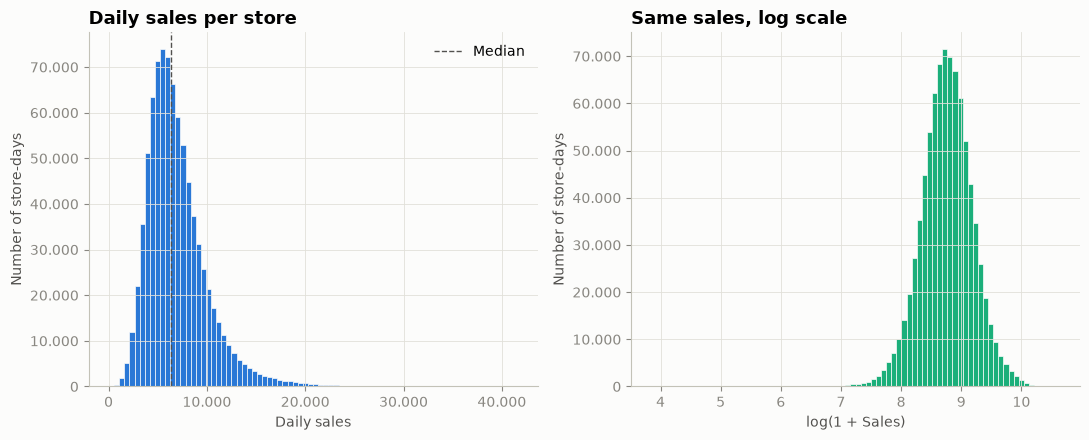

In [31]:
# 1. Sales over time

fig, ax = plt.subplots(1, 2)
ax[0].hist(tr["Sales"], bins=80, color=COL[0], edgecolor="#fcfcfb", linewidth=0.5)
ax[0].axvline(tr["Sales"].median(), color="#52514e", ls="--", lw=1, label="Median")
ax[0].set_title("Daily sales per store")
ax[0].set_xlabel("Daily sales"); ax[0].set_ylabel("Number of store-days")
ax[0].xaxis.set_major_formatter(miles); ax[0].yaxis.set_major_formatter(miles)
ax[0].legend(frameon=False)

ax[1].hist(np.log1p(tr["Sales"]), bins=80, color=COL[2], edgecolor="#fcfcfb", linewidth=0.5)
ax[1].set_title("Same sales, log scale")
ax[1].set_xlabel("log(1 + Sales)"); ax[1].set_ylabel("Number of store-days")
ax[1].yaxis.set_major_formatter(miles)
plt.tight_layout(); plt.show()

<b>Sales distribution</b>

Left: a histogram of daily sales. Each bar counts how many store-days fell in that sales range. Most days sit between 3,000 and 10,000 (median ≈ 5,700), with a long tail to the right: a few days with very high sales. The distribution is right-skewed (skewness ≈ 1.6)</br>
Right: the same data after taking log(1 + Sales). The shape becomes almost symmetric (skewness ≈ −0.1).

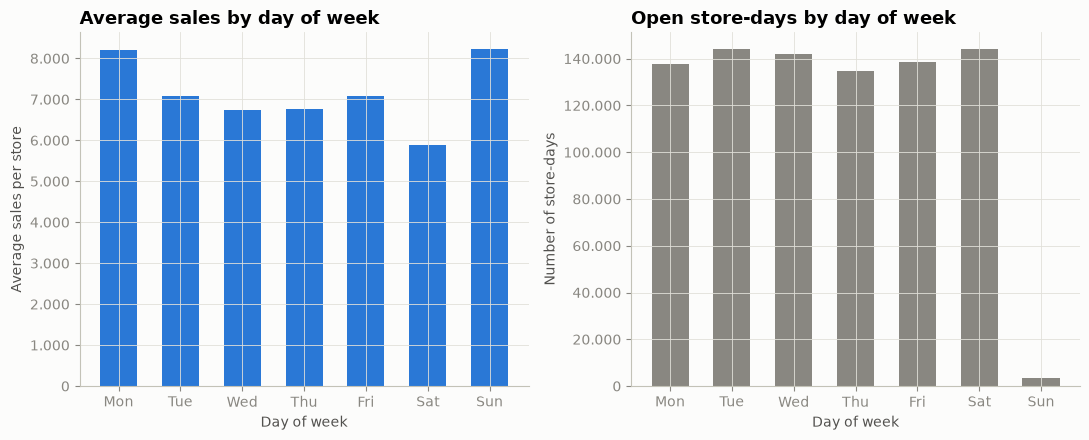

            sales       n
DayOfWeek                
1          8216.0  137557
2          7088.0  143955
3          6729.0  141922
4          6768.0  134626
5          7073.0  138633
6          5875.0  144052
7          8225.0    3593


In [32]:
# 2. Sales by day of week
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

dow = tr.groupby("DayOfWeek").agg(sales=("Sales", "mean"), n=("Sales", "size"))

fig, ax = plt.subplots(1, 2)
ax[0].bar(DAYS, dow["sales"], color=COL[0], width=0.6)
ax[0].set_title("Average sales by day of week")
ax[0].set_xlabel("Day of week"); ax[0].set_ylabel("Average sales per store")
ax[0].yaxis.set_major_formatter(miles)

ax[1].bar(DAYS, dow["n"], color="#898781", width=0.6)
ax[1].set_title("Open store-days by day of week")
ax[1].set_xlabel("Day of week"); ax[1].set_ylabel("Number of store-days")
ax[1].yaxis.set_major_formatter(miles)
plt.tight_layout(); plt.show()
print(dow.round(0))

<b>Sales by day of week</b>

Left (blue): average sales per store for each day of the week. Monday is the strongest day (~8,200), Saturday the weakest (~5,900), and Tuesday to Friday are similar (~6,700–7,100).</br>
Right (gray): how many open store-days exist for each day. Monday to Saturday each have ~140,000, but Sunday has only ~3,600.</br>

Takeaway: day of week matters for sales. The high Sunday bar is misleading, though: it comes from a small group of special stores that open on Sundays, not from Sundays in general. Monday’s lead may be driven by promotions, since promo weeks start on Monday. Chart 2.2 checks that.

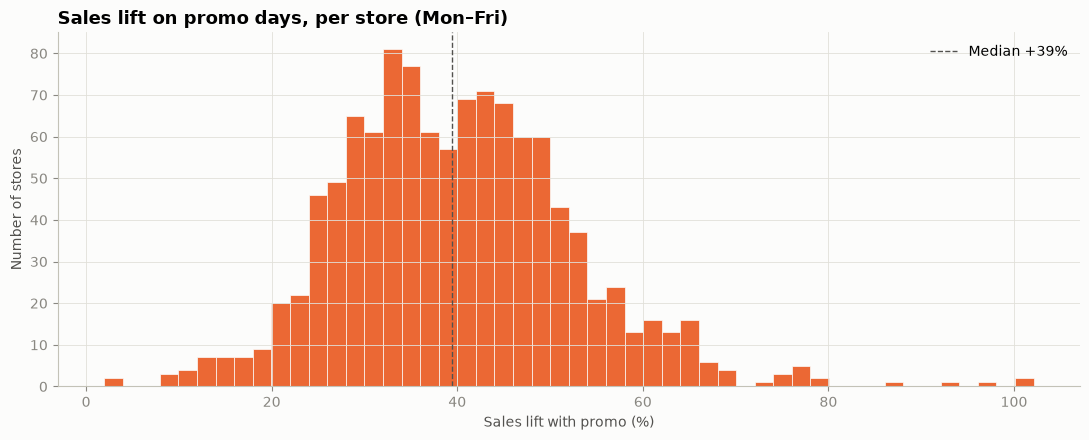

count    1115.00
mean        0.40
std         0.13
min         0.02
25%         0.31
50%         0.39
75%         0.48
max         1.02
Name: Lift, dtype: float64
       NoPromo    Promo  Lift StoreType
Store                                  
789    3456.30  3523.24  0.02         a
794    3169.69  3242.84  0.02         c
274    3580.13  3891.88  0.09         b
948    6470.84  7071.45  0.09         b
353    5305.60  5799.30  0.09         b
       NoPromo    Promo  Lift StoreType
Store                                  
575    4074.87  7586.11  0.86         a
636    4086.37  7906.77  0.93         c
543    1986.69  3926.07  0.98         c
693    4535.59  9107.82  1.01         d
198    2124.98  4294.73  1.02         a


In [33]:
#3. Sales w/promo by store

wd = tr[tr["DayOfWeek"] <= 5]   # only Mon-Fri 

lift = wd.groupby(["Store", "Promo"])["Sales"].mean().unstack()
lift.columns = ["NoPromo", "Promo"]
lift["Lift"] = lift["Promo"] / lift["NoPromo"] - 1
lift["StoreType"] = tr.drop_duplicates("Store").set_index("Store")["StoreType"]

fig, ax = plt.subplots()
ax.hist(lift["Lift"] * 100, bins=50, color=COL[1], edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(lift["Lift"].median() * 100, color="#52514e", ls="--", lw=1,
           label=f"Median +{lift['Lift'].median():.0%}")
ax.set_title("Sales lift on promo days, per store (Mon–Fri)")
ax.set_xlabel("Sales lift with promo (%)"); ax.set_ylabel("Number of stores")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(lift["Lift"].describe().round(2))
print(lift.sort_values("Lift").head(5).round(2))   
print(lift.sort_values("Lift").tail(5).round(2))  

<b>Summary:</b> promos lift sales by about 40% for a typical store, and most stores fall between +31% and +48%. There are extremes: some stores barely react (+2%), while others double their sales (+100%). Because the promo effect varies a lot from store to store, the model needs to be able to learn a different lift for each store.

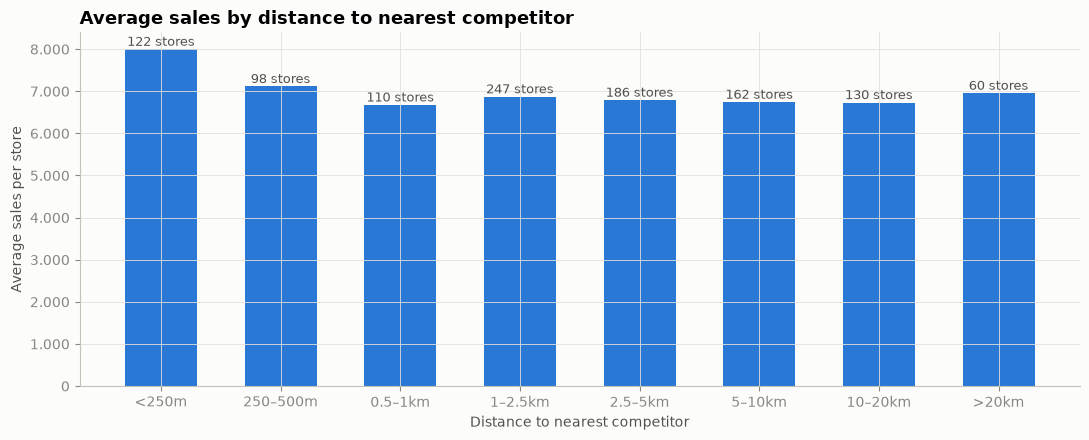

In [34]:
#6. Competitor effect

bins   = [0, 250, 500, 1000, 2500, 5000, 10000, 20000, 100001]
labels = ["<250m", "250–500m", "0.5–1km", "1–2.5km", "2.5–5km", "5–10km", "10–20km", ">20km"]
tr["CompDistBin"] = pd.cut(tr["CompetitionDistance"], bins=bins, labels=labels)

d = tr.groupby("CompDistBin", observed=True).agg(sales=("Sales", "mean"), stores=("Store", "nunique"))

fig, ax = plt.subplots()
ax.bar(d.index.astype(str), d["sales"], color=COL[0], width=0.6)
for i, (v, n) in enumerate(zip(d["sales"], d["stores"])):
    ax.text(i, v + 80, f"{n} stores", ha="center", color="#52514e", fontsize=9)
ax.set_title("Average sales by distance to nearest competitor")
ax.set_xlabel("Distance to nearest competitor"); ax.set_ylabel("Average sales per store")
ax.yaxis.set_major_formatter(miles)
plt.tight_layout(); plt.show()

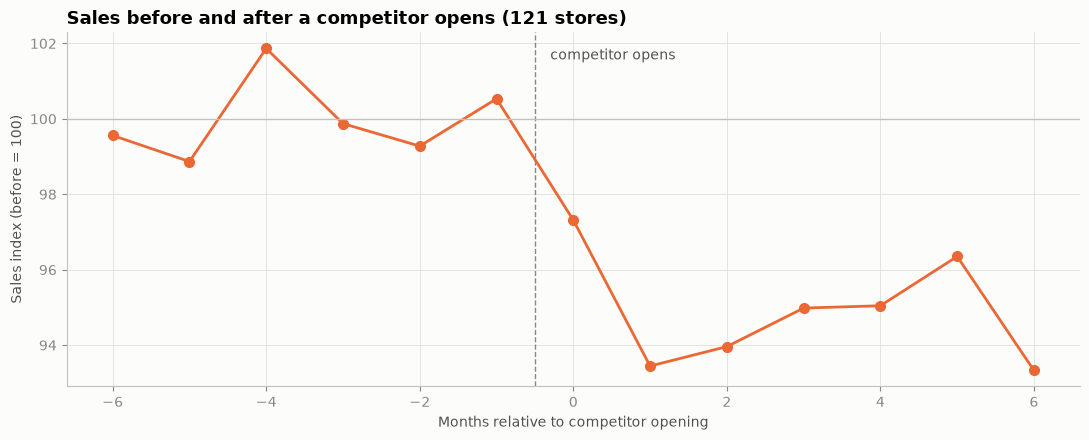

In [35]:
op = tr.groupby("Store")["CompetitionOpenMonths"].agg(["min", "max"])
new = op[(op["min"] <= -6) & (op["max"] >= 6)].index      # 6 meses de datos antes y después

ev = tr[tr["Store"].isin(new) & tr["CompetitionOpenMonths"].between(-6, 6)].copy()
base = ev[ev["CompetitionOpenMonths"] < 0].groupby("Store")["Sales"].mean()
ev["SalesIdx"] = ev["Sales"] / ev["Store"].map(base) * 100   # antes = 100

e = ev.groupby("CompetitionOpenMonths")["SalesIdx"].mean()

fig, ax = plt.subplots()
ax.plot(e.index, e.values, marker="o", ms=7, color=COL[1])
ax.axvline(-0.5, color="#898781", ls="--", lw=1)
ax.text(-0.3, e.max(), "competitor opens", color="#52514e", va="top")
ax.axhline(100, color="#c3c2b7", lw=1)
ax.set_title(f"Sales before and after a competitor opens ({len(new)} stores)")
ax.set_xlabel("Months relative to competitor opening"); ax.set_ylabel("Sales index (before = 100)")
plt.tight_layout(); plt.show()

<b>Sumamry:</b> The distance to the nearest competitor alone barely explains sales. Stores with a very close competitor (<250 m) actually sell more, because they are in busy central areas. The real competition effect shows up over time: when a new competitor opens, the store’s sales drop by about 5–7% and stay lower for at least 6 months. For the model, CompetitionOpenMonths and CompetitionActive matter more than the distance itself.

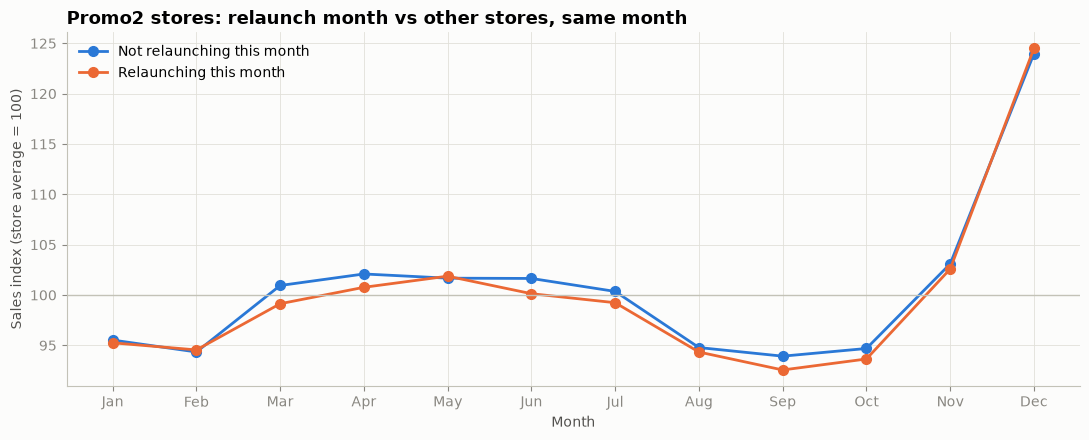

In [36]:
# 7. Effect of Promo2
tr["Month"] = tr["Date"].dt.month

p2 = tr[tr["Promo2Active"] == 1].copy()
p2["SalesIdx"] = p2["Sales"] / p2.groupby("Store")["Sales"].transform("mean") * 100

m = p2.groupby(["Month", "Promo2Month"])["SalesIdx"].mean().unstack()

fig, ax = plt.subplots()
ax.plot(range(12), m[0], marker="o", ms=7, color=COL[0], label="Not relaunching this month")
ax.plot(range(12), m[1], marker="o", ms=7, color=COL[1], label="Relaunching this month")
ax.axhline(100, color="#c3c2b7", lw=1)
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Promo2 stores: relaunch month vs other stores, same month")
ax.set_xlabel("Month"); ax.set_ylabel("Sales index (store average = 100)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

<b>Summary:</b> The Promo2 relaunch month does not increase sales. Compared within the same calendar month, stores that are relaunching sell the same as Promo2 stores that are not. Promo2 stores sell less overall, but that is because Rossmann assigns Promo2 to weaker stores, not because Promo2 hurts sales. For the model, Promo2Month will likely add little; the daily Promo is what really matters.

In [37]:
# 8. Analisys Aug - Sep 2013-2014 - only the stores with data in those months

in_gap = tr.loc[tr["Date"].between("2014-07-01", "2014-12-31"), "Store"].unique()
t = tr[tr["Store"].isin(in_gap)].copy()     
print(t["Store"].nunique())                 


935


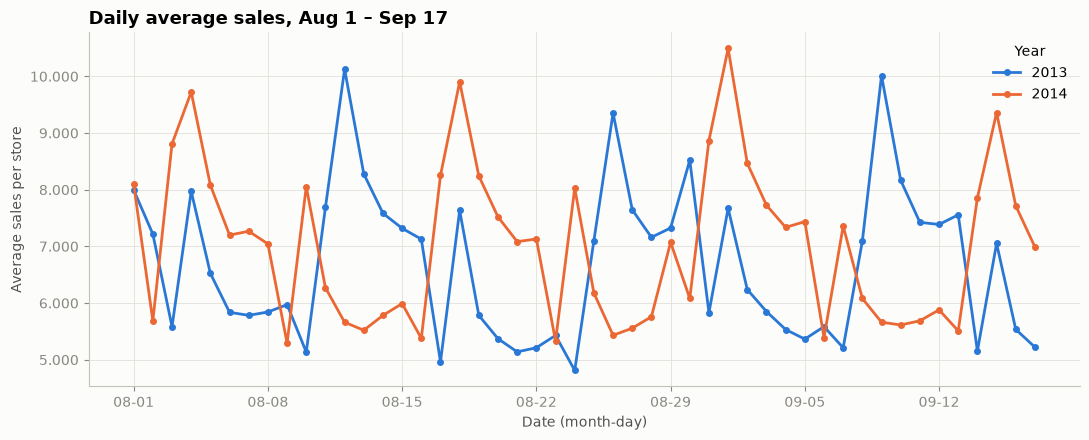

In [38]:
fig, ax = plt.subplots()
for i, y in enumerate([2013, 2014]):
    d = t[(t["Date"] >= f"{y}-08-01") & (t["Date"] <= f"{y}-09-17")]
    s = d.groupby("Date")["Sales"].mean()
    ax.plot(s.index.strftime("%m-%d"), s.values, marker="o", ms=4, color=COL[i], label=str(y))
ax.set_xticks(range(0, 48, 7))
ax.set_title("Daily average sales, Aug 1 – Sep 17")
ax.set_xlabel("Date (month-day)"); ax.set_ylabel("Average sales per store")
ax.yaxis.set_major_formatter(miles); ax.legend(frameon=False, title="Year")
plt.tight_layout(); plt.show()

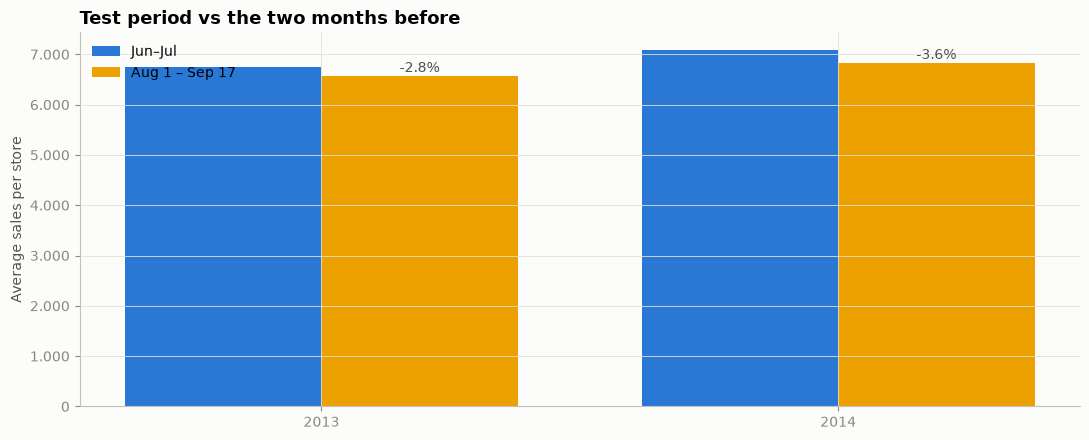

        JunJul    AugSep  change
Year                            
2013  6756.199  6568.924  -0.028
2014  7083.355  6827.508  -0.036


In [39]:
rows = []
for y in [2013, 2014]:
    before = t[(t["Date"] >= f"{y}-06-01") & (t["Date"] <= f"{y}-07-31")]["Sales"].mean()
    during = t[(t["Date"] >= f"{y}-08-01") & (t["Date"] <= f"{y}-09-17")]["Sales"].mean()
    rows.append((y, before, during))
r = pd.DataFrame(rows, columns=["Year", "JunJul", "AugSep"]).set_index("Year")
r["change"] = r["AugSep"] / r["JunJul"] - 1

x = np.arange(2); w = 0.38
fig, ax = plt.subplots()
ax.bar(x - w/2, r["JunJul"], width=w, color=COL[0], label="Jun–Jul")
ax.bar(x + w/2, r["AugSep"], width=w, color=COL[3], label="Aug 1 – Sep 17")
for i, (v, c) in enumerate(zip(r["AugSep"], r["change"])):
    ax.text(i + w/2, v + 80, f"{c:+.1%}", ha="center", color="#52514e")
ax.set_xticks(x, ["2013", "2014"])
ax.set_title("Test period vs the two months before")
ax.set_ylabel("Average sales per store"); ax.yaxis.set_major_formatter(miles)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(r.round(3))

<b>Summary: </b>
August to mid-September behaves very consistently across years. Sales are about 3% lower than in June–July (summer holidays), and daily sales follow the promo calendar (peaks in promo weeks, valleys in between) rather than the calendar date. The promo lift in this period (~40%) matches the rest of the year. Since we know the 2015 promo calendar for the test period, these patterns should make the test period quite predictable.

### Feature selection
1. Predictors selected
2. Transformation in both train/test
3. Split only Aug-Sep from train for validation 

In [40]:
# 1.Features var
def add_features(df):
    df = df.copy()
    df["Year"]       = df["Date"].dt.year
    df["Month"]      = df["Date"].dt.month
    df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
    df["DayOfMonth"] = df["Date"].dt.day
    df["PromoDay"]   = np.where(df["Promo"] == 1, df["DayOfWeek"], 0)

    # same in train and test
    df["StoreType"]    = pd.Categorical(df["StoreType"],    categories=["a", "b", "c", "d"])
    df["Assortment"]   = pd.Categorical(df["Assortment"],   categories=["a", "b", "c"])
    df["StateHoliday"] = pd.Categorical(df["StateHoliday"], categories=["0", "a", "b", "c"])
    return df

train = add_features(pd.read_parquet(base_path / "clean" / "train_clean.parquet"))
test  = add_features(pd.read_parquet(base_path / "clean" / "test_clean.parquet"))

FEATURES = [
    "Store", "StoreType", "Assortment",
    "DayOfWeek", "Year", "Month", "WeekOfYear", "DayOfMonth",
    "Promo", "PromoDay",
    "StateHoliday", "SchoolHoliday",
    "ClosedYesterday", "ClosedTomorrow", "DaysSinceClosed", "DaysToClosed",
    "CompetitionDistance", "CompetitionOpenMonths", "CompetitionActive", "CompOpenMissing",
    "Promo2", "Promo2Weeks", "Promo2Month",
]

X      = train[FEATURES]
y      = np.log1p(train["Sales"])     # target en log
X_test = test[FEATURES]

In [41]:
print(X.shape, X_test.shape)                       
print(set(FEATURES) - set(test.columns))           
print(X.isna().sum()[X.isna().sum() > 0])          
print(X.dtypes.value_counts())

(844338, 23) (41088, 23)
set()
CompetitionOpenMonths    268600
dtype: int64
int64       15
int32        3
float64      2
category     1
category     1
category     1
Name: count, dtype: int64


### Models to implement
1. Linear Regression
2. Random Forest
3. XGBoost
4. Hyperparameter Optimization (in XGBoost)

In [42]:
# Model 1. Linear Regression
def rmspe(y_true, y_pred):
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2))

VAL_START = "2015-06-19"                     # last 6 weeks = validación
trn = train[train["Date"] <  VAL_START]
val = train[train["Date"] >= VAL_START]
print(len(trn), len(val))                    # 802942  41396

802942 41396


In [43]:
# Prepare data
def prep_linear(df):
    df = df.copy()
    df["CompetitionOpenMonths"] = df["CompetitionOpenMonths"].fillna(0).clip(-12, 120)
    df["LogCompDist"] = np.log1p(df["CompetitionDistance"])
    return df

trn_l = prep_linear(trn)
val_l = prep_linear(val)

CAT = ["Store", "DayOfWeek", "Month", "DayOfMonth", "PromoDay",
       "StateHoliday", "StoreType", "Assortment", "Year"]
NUM = ["Promo", "SchoolHoliday", "ClosedYesterday", "ClosedTomorrow",
       "DaysSinceClosed", "DaysToClosed", "LogCompDist", "CompetitionOpenMonths",
       "CompetitionActive", "Promo2", "Promo2Weeks", "Promo2Month"]

In [44]:
# Train - Evaluation
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

linreg = make_pipeline(
    ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler(), NUM),
    ]),
    LinearRegression()
)

linreg.fit(trn_l[CAT + NUM], np.log1p(trn_l["Sales"]))      # train in log

pred_lin = np.expm1(linreg.predict(val_l[CAT + NUM]))       # back to real sales numbers
print("Linear Regression RMSPE:", rmspe(val_l["Sales"], pred_lin).round(4))

Linear Regression RMSPE: 0.2039


In [45]:
# Model 2. Random Forest
# Prepare data
from sklearn.ensemble import RandomForestRegressor

def prep_tree(df):
    X = df[FEATURES].copy()
    for c in ["StoreType", "Assortment", "StateHoliday"]:
        X[c] = X[c].cat.codes                                     # a→0, b→1, c→2...
    X["CompetitionOpenMonths"] = X["CompetitionOpenMonths"].fillna(-999)
    return X

X_trn = prep_tree(trn)
X_val = prep_tree(val)

In [46]:
rf = RandomForestRegressor(
    n_estimators=50,        # number of trees
    max_samples=0.3,        # each tree trains on a random 30% of the rows → faster
    min_samples_leaf=3,     # each leaf needs at least 3 rows → prevents memorizing
    max_features=0.7,       # each split chooses from 70% of the features → more diverse trees
    n_jobs=-1,              # use all CPU cores
    random_state=42,        # reproducible results
)
rf.fit(X_trn, np.log1p(trn["Sales"]))          # train on log(Sales)

pred_rf = np.expm1(rf.predict(X_val))          # back to real sales
print("Random Forest RMSPE:", rmspe(val["Sales"], pred_rf).round(4))

Random Forest RMSPE: 0.1439


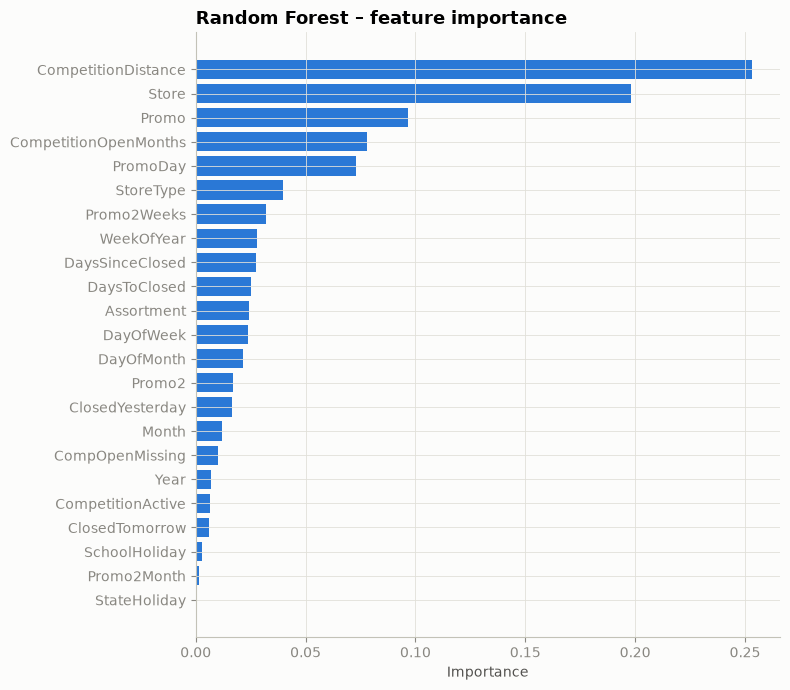

In [51]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp.values, color=COL[0])
ax.set_title("Random Forest – feature importance")
ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

In [52]:
# Model 3. XGBoost
# Prepare data

import xgboost as xgb      # if missing: pip install xgboost

def prep_xgb(df):
    X = df[FEATURES].copy()
    for c in ["StoreType", "Assortment", "StateHoliday"]:
        X[c] = X[c].cat.codes        # categories → numbers
    return X

X_trn = prep_xgb(trn)
X_val = prep_xgb(val)

In [53]:
xgb_model = xgb.XGBRegressor(
    n_estimators=3000,          # max number of trees (early stopping picks the best)
    learning_rate=0.1,          # how much each new tree corrects the previous ones
    max_depth=10,               # max depth of each tree
    subsample=0.9,              # each tree uses a random 90% of the rows
    colsample_bytree=0.7,       # each tree uses a random 70% of the features
    min_child_weight=3,         # minimum data in a leaf → prevents memorizing
    tree_method="hist",         # fast histogram-based algorithm
    early_stopping_rounds=100,  # stop if validation doesn't improve for 100 trees
    n_jobs=-1,                  # use all CPU cores
    random_state=42,            # reproducible results
)

xgb_model.fit(
    X_trn, np.log1p(trn["Sales"]),
    eval_set=[(X_val, np.log1p(val["Sales"]))],   # monitor validation error while training
    verbose=500,                                  # print progress every 500 trees
)

pred_xgb = np.expm1(xgb_model.predict(X_val))     # back to real sales
print("Best number of trees:", xgb_model.best_iteration)
print("XGBoost RMSPE:", rmspe(val["Sales"], pred_xgb).round(4))

[0]	validation_0-rmse:0.39753
[500]	validation_0-rmse:0.11921
[1000]	validation_0-rmse:0.11719
[1298]	validation_0-rmse:0.11692
Best number of trees: 1198
XGBoost RMSPE: 0.1217


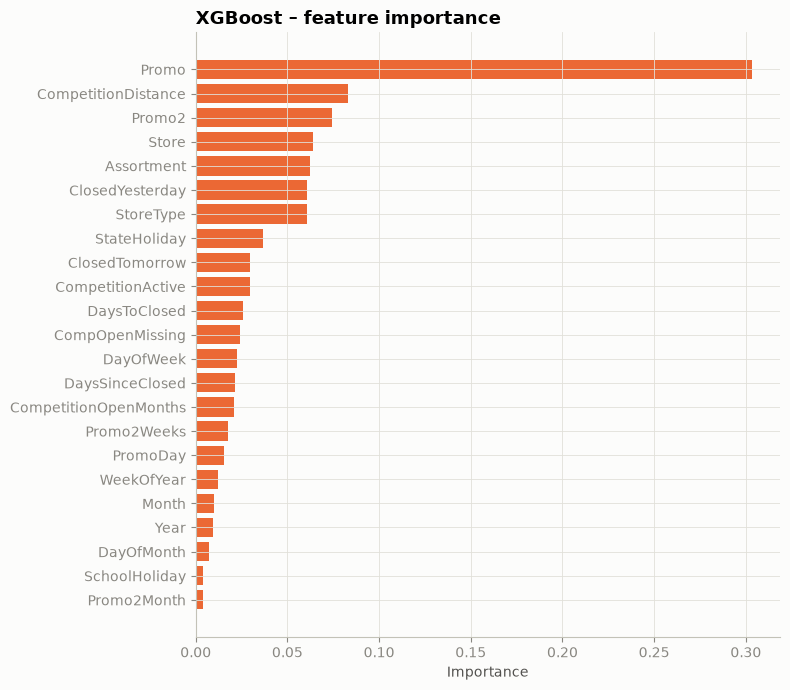

In [54]:
imp_xgb = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp_xgb.index, imp_xgb.values, color=COL[1])
ax.set_title("XGBoost – feature importance")
ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

In [55]:
# 4. Optimization

import time

BASE = dict(n_estimators=3000, learning_rate=0.1, max_depth=10, subsample=0.9,
            colsample_bytree=0.7, min_child_weight=3, tree_method="hist",
            early_stopping_rounds=100, n_jobs=-1, random_state=42)

results = []

def run_xgb(name, features=FEATURES, **changes):
    params = {**BASE, **changes}                     # base params + the ones we change

    def prep(df):
        X = df[features].copy()
        for c in X.select_dtypes("category").columns:
            X[c] = X[c].cat.codes                    # categories → numbers
        return X

    t0 = time.time()
    model = xgb.XGBRegressor(**params)
    model.fit(prep(trn), np.log1p(trn["Sales"]),
              eval_set=[(prep(val), np.log1p(val["Sales"]))], verbose=False)
    pred = np.expm1(model.predict(prep(val)))

    res = {"name": name,
           "rmspe": rmspe(val["Sales"], pred),
           "rmspe_x0.985": rmspe(val["Sales"], pred * 0.985),   # with correction factor
           "trees": model.best_iteration,
           "minutes": (time.time() - t0) / 60}
    results.append(res)
    print(res)
    return model

In [56]:
run_xgb("baseline")

{'name': 'baseline', 'rmspe': np.float64(0.12165550659671276), 'rmspe_x0.985': np.float64(0.1200270201142924), 'trees': 1198, 'minutes': 0.8273456215858459}


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [57]:
run_xgb("depth 8",  max_depth=8)

{'name': 'depth 8', 'rmspe': np.float64(0.1259624986152729), 'rmspe_x0.985': np.float64(0.12381204983322694), 'trees': 1068, 'minutes': 0.5745047688484192}


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [58]:
run_xgb("colsample 0.5", colsample_bytree=0.5)

{'name': 'colsample 0.5', 'rmspe': np.float64(0.12223135013117745), 'rmspe_x0.985': np.float64(0.12071653714343161), 'trees': 1876, 'minutes': 1.2814776698748271}


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.5
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [59]:
run_xgb("min_child_weight 10", min_child_weight=10)

{'name': 'min_child_weight 10', 'rmspe': np.float64(0.12340323312662681), 'rmspe_x0.985': np.float64(0.12201326340724344), 'trees': 1370, 'minutes': 0.8976407170295715}


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [60]:
run_xgb("no Promo2Month/SchoolHoliday",
        features=[f for f in FEATURES if f not in ["Promo2Month", "SchoolHoliday"]])

{'name': 'no Promo2Month/SchoolHoliday', 'rmspe': np.float64(0.12498455391322168), 'rmspe_x0.985': np.float64(0.12387986732021412), 'trees': 1305, 'minutes': 0.8309611598650615}


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [61]:
run_xgb("lr 0.05", learning_rate=0.05);

{'name': 'lr 0.05', 'rmspe': np.float64(0.12276774120130513), 'rmspe_x0.985': np.float64(0.12129108923379268), 'trees': 2178, 'minutes': 1.4159926692644755}


In [62]:
res = pd.DataFrame(results).sort_values("rmspe_x0.985")
print(res.round(4))

                           name   rmspe  rmspe_x0.985  trees  minutes
0                      baseline  0.1217        0.1200   1198   0.8273
2                 colsample 0.5  0.1222        0.1207   1876   1.2815
5                       lr 0.05  0.1228        0.1213   2178   1.4160
3           min_child_weight 10  0.1234        0.1220   1370   0.8976
1                       depth 8  0.1260        0.1238   1068   0.5745
4  no Promo2Month/SchoolHoliday  0.1250        0.1239   1305   0.8310



<b>XGBoost tuning</b>

We started from our first XGBoost model (validation RMSPE 0.1217) and changed one parameter at a time to see whether anything improved it. We kept the same 6-week validation period so every result was comparable, and we also scored each model with a 0.985 correction factor.

What we tested:
- Shallower trees (max_depth 8): worse. The model needs deep trees to capture store × promo × day combinations.
- Fewer features per tree (colsample_bytree 0.5): a tie, within random noise.
- More conservative leaves (min_child_weight 10): slightly worse.
- Slower learning (learning_rate 0.05): no gain, and it needed more trees.
- Dropping Promo2Month and SchoolHoliday: worse, so low importance didn’t mean useless.

<b>Result:</b> none of the changes beat the original setup, so we keep the baseline model, which scores 0.1200 RMSPE with the correction factor. Once XGBoost is reasonably configured, parameter tuning brings only small gains, and bigger improvements usually come from better features.

### Generate file with Ago - Sep
1. Re-train with the hold train dataset (included the last 6 weeks used to validation)
2. Sales Prediccion in test
3. Create the file

In [64]:
# 1. Re-train train + validation

t0 = time.time()
def prep(df):
    X = df[FEATURES].copy()
    for c in X.select_dtypes("category").columns:
        X[c] = X[c].cat.codes          # categories → numbers
    return X

final_model = xgb.XGBRegressor(
    n_estimators=1250,          # best iteration (~1200) + a bit more, since there is more data
    learning_rate=0.1, max_depth=10, subsample=0.9, colsample_bytree=0.7,
    min_child_weight=3, tree_method="hist", n_jobs=-1, random_state=42,
)

final_model.fit(prep(train), np.log1p(train["Sales"]))      # ALL train: trn + val

pred_all = np.expm1(final_model.predict(prep(train)))

print({"name": "final (all train)",
       "rmspe_train": rmspe(train["Sales"], pred_all),
       "rmspe_train_x0.985": rmspe(train["Sales"], pred_all * 0.985),
       "trees": final_model.get_booster().num_boosted_rounds(),
       "minutes": (time.time() - t0) / 60})

{'name': 'final (all train)', 'rmspe_train': np.float64(0.06782192487149388), 'rmspe_train_x0.985': np.float64(0.06802937921658392), 'trees': 1250, 'minutes': 0.7671520511309305}


In [65]:
# 2. Sales prediction for test

pred_test = np.expm1(final_model.predict(prep(test)))   # back to real sales
pred_test = pred_test * 0.985                           # correction factor
pred_test = np.where(test["Open"] == 0, 0, pred_test)   # closed days → 0 sales

In [66]:
submission = pd.DataFrame({"Id": test["Id"], "Sales": pred_test}).sort_values("Id")

print(submission.shape)                        # (41088, 2)
print(submission["Sales"].isna().sum())        # 0
print((submission["Sales"] == 0).sum())        # 5984 → the closed days
print(submission.loc[test.sort_values("Id")["Open"].values == 1, "Sales"].mean().round(0))
submission.head()

(41088, 2)
0
5984
6773.0


,Id,Sales
0,1,4959.739746
1,2,7080.125000
2,3,8819.485352
3,4,7006.302734
4,5,7214.672363


In [67]:
# 3. Create/save the file
submission.to_csv(base_path / "submission.csv", index=False)

In [72]:
test["PredSales"] = pred_test                  
open_days = test[test["Open"] == 1] # predicted sales (0 on closed days)

monthly = open_days.pivot_table(index="Store", columns="Month",
                                values="PredSales", aggfunc="mean").round(0)
monthly.columns = ["Aug", "Sep"]
monthly["Change_%"] = ((monthly["Sep"] / monthly["Aug"] - 1) * 100).round(1)

print(monthly.describe().round(1))

           Aug      Sep  Change_%
count    856.0    856.0     856.0
mean    6766.9   6742.6      -0.0
std     2141.9   2080.4       4.0
min     2539.0   2800.0     -15.9
25%     5328.0   5343.8      -2.3
50%     6405.0   6421.0      -0.1
75%     7812.0   7671.5       2.3
max    22581.0  21463.0      20.4


In [73]:
months_15 = train[(train["Date"] >= "2015-01-01") &
                  (train["Store"].isin(test["Store"].unique()))]

monthly_jj = months_15.pivot_table(index="Store", columns="Month",
                                   values="Sales", aggfunc="mean").round(0)
monthly_jj.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"]

print(monthly_jj.describe().round(1))

           Jan      Feb      Mar      Apr      May      Jun      Jul
count    856.0    856.0    856.0    856.0    856.0    856.0    856.0
mean    6820.0   6577.1   6982.0   7245.0   7230.3   7243.9   6947.3
std     2220.6   2215.9   2321.6   2390.2   2431.2   2416.4   2326.1
min     2728.0   2478.0   3028.0   2793.0   2597.0   2969.0   2603.0
25%     5330.5   5105.0   5414.0   5673.8   5605.5   5642.2   5439.2
50%     6484.5   6239.5   6623.0   6888.0   6883.0   6871.0   6520.5
75%     7850.0   7584.0   8044.2   8349.2   8289.0   8379.2   8009.5
max    20222.0  20140.0  20877.0  23279.0  23345.0  22199.0  23207.0


In [74]:
test_stores = test["Store"].unique()

for y in [2013, 2014]:
    months_y = train[(train["Date"] >= f"{y}-08-01") & (train["Date"] <= f"{y}-09-17") &
                     (train["Store"].isin(test_stores))]

    monthly_y = months_y.pivot_table(index="Store", columns="Month",
                                     values="Sales", aggfunc="mean").round(0)
    monthly_y.columns = ["Aug", "Sep"]
    monthly_y["Change_%"] = ((monthly_y["Sep"] / monthly_y["Aug"] - 1) * 100).round(1)

    print(f"\n===== Aug–Sep {y} (actual) =====")
    print(monthly_y.describe().round(1))


===== Aug–Sep 2013 (actual) =====
           Aug      Sep  Change_%
count    856.0    855.0     855.0
mean    6503.4   6307.9      -2.9
std     2210.8   2209.4       7.9
min     2289.0   2299.0     -31.7
25%     4994.5   4839.5      -7.0
50%     6149.5   5931.0      -2.8
75%     7562.2   7197.5       1.1
max    20713.0  21001.0      87.9

===== Aug–Sep 2014 (actual) =====
           Aug      Sep  Change_%
count    676.0    676.0     676.0
mean    6668.7   6909.8       4.1
std     2286.5   2317.8       7.5
min     2532.0   2861.0     -33.0
25%     5083.0   5337.8       0.9
50%     6410.0   6634.5       4.7
75%     7875.5   7997.8       8.3
max    21122.0  20358.0      91.3


<b>Conclusions:</b>
The forecast is consistent with past behavior. Every year, August–September sells less than June–July (−3.1% in 2013 and −2.9% in 2014), and the model captures that summer slowdown. It also picks up the downward trend already visible in July 2015: compared with July alone, August drops about 2.6%, in line with history.

If anything, the forecast may be slightly pessimistic. The predicted drop versus June–July (about −4.8%) is larger than in either previous year. In absolute terms, the August forecast (6,767) sits above August 2013 and 2014, consistent with year-over-year growth. September (6,743), however, comes in below September 2014 (6,910). Note that the 2014 figure covers only 676 stores, so the comparison is approximate. September also has a higher share of promo days in 2015, so without that boost it would come out a little lower still.

The month-to-month pattern differs between years: September was below August in 2013 and above it in 2014. So the flat August-to-September forecast for 2015 is within the normal range.